# A/B-тест новой карточки товара на сайте

**Контекст.** На сайте магазина товаров для дома конверсия из просмотра карточки в заказ — около 3%. Команда сделала новую карточку: короткое видео товара и блок «Как выглядит в интерьере». Видео и фотосъёмка для всех товаров стоят денег, поэтому собственник спрашивает: **«Окупится ли это, или конверсия вырастет только на словах?»**

**Гипотеза.** Новая карточка повышает конверсию в заказ, потому что покупатель лучше понимает размер и цвет товара.

| Метрика | Роль | Что считаем |
|---|---|---|
| Конверсия в заказ | **основная** | доля посетителей, оформивших заказ |
| Выручка на посетителя (ARPU) | дополнительная | выручка / все посетители группы |
| Средний чек | контрольная | не должен упасть |
| Доля возвратов | контрольная | не должна вырасти: видео не должно создавать завышенных ожиданий |

**План.** Рассчитать размер выборки до теста → проверить корректность разбиения → проверить основную метрику → посмотреть дополнительные и контрольные → принять решение и посчитать деньги.

> Данные синтетические, сгенерированы скриптом [`data/generate.py`](../../data/generate.py): истинный эффект заложен в генератор, поэтому можно проверить, находит ли его анализ.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e3",
    "axes.axisbelow": True, "axes.edgecolor": "#9a9993", "figure.facecolor": "white",
})
A_COL, B_COL = "#9a9993", "#2a78d6"     # контроль — нейтральный серый, тест — акцентный синий
rng = np.random.default_rng(1)
ALPHA, POWER = 0.05, 0.80
pd.set_option("display.max_columns", 20); pd.set_option("display.width", 200)

## 1. Дизайн теста: сколько нужно посетителей

До запуска фиксирую параметры, чтобы не подгонять их под результат:
- базовая конверсия — **3,25%** (по данным сайта за прошлый месяц);
- минимальный эффект, ради которого стоит снимать видео (MDE), — **+0,6 п.п.**, то есть +18% к конверсии. Меньший рост не окупит съёмку: расчёт в конце;
- уровень значимости α = 5%, мощность 80%, двусторонняя проверка.

In [2]:
def sample_size(p1, mde, alpha=ALPHA, power=POWER):
    """Размер каждой группы для сравнения двух долей (нормальная аппроксимация)."""
    p2 = p1 + mde
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    p_bar = (p1 + p2) / 2
    n = (z_a * np.sqrt(2 * p_bar * (1 - p_bar)) + z_b * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / mde ** 2
    return int(np.ceil(n))

n_needed = sample_size(0.0325, 0.006)
print(f"Нужно посетителей в каждой группе: {n_needed:,}".replace(",", " "))
print(f"При ~1 150 посетителях карточек в день тест займёт ≈ {2 * n_needed / 1150:.0f} дней → запускаем на 4 полные недели")

for mde in [0.004, 0.005, 0.006, 0.008]:
    print(f"  MDE +{mde*100:.1f} п.п. → {sample_size(0.0325, mde):>7,} на группу".replace(",", " "))

Нужно посетителей в каждой группе: 14 930
При ~1 150 посетителях карточек в день тест займёт ≈ 26 дней → запускаем на 4 полные недели
  MDE +0.4 п.п. →  32 680 на группу
  MDE +0.5 п.п. →  21 207 на группу
  MDE +0.6 п.п. →  14 930 на группу
  MDE +0.8 п.п. →   8 625 на группу


Тест на 4 полные недели, чтобы каждый день недели попал в обе группы одинаково. Смотреть результат до окончания нельзя: о «подглядывании» — в разделе 6.

## 2. Данные и проверка корректности разбиения

In [3]:
ab = pd.read_csv("../../data/ab_test.csv", parse_dates=["first_visit"])
print(f"Посетителей: {len(ab):,}; период: {ab.first_visit.min():%d.%m} — {ab.first_visit.max():%d.%m.%Y}".replace(",", " "))
print("Дубли пользователей:", ab.user_id.duplicated().sum())
ab.head()

Посетителей: 32 000; период: 04.08 — 31.08.2026
Дубли пользователей: 0


,user_id,group,first_visit,device,source,converted,revenue,returned
0,531946,A,2026-08-30,desktop,реклама,0,0.0,0
1,518589,A,2026-08-27,mobile,поиск,0,0.0,0
2,519086,B,2026-08-27,desktop,поиск,0,0.0,0
3,511461,A,2026-08-14,mobile,реклама,0,0.0,0
4,526339,B,2026-08-10,desktop,реклама,0,0.0,0


**Sample Ratio Mismatch (SRM).** Трафик делили 50/50. Если фактическое соотношение заметно отличается, значит, сломана система разбиения (например, у одной группы чаще падала страница), и результатам теста верить нельзя. Проверяю критерием хи-квадрат.

In [4]:
counts = ab.group.value_counts().sort_index()
chi2, p_srm = stats.chisquare(counts)
print(counts.to_string())
print(f"\nДоля группы B: {counts['B'] / counts.sum():.2%}; χ² = {chi2:.2f}, p-value = {p_srm:.3f}")
print("SRM не обнаружен ✓" if p_srm > 0.01 else "ВНИМАНИЕ: SRM — результаты теста недостоверны")

group
A    16155
B    15845

Доля группы B: 49.52%; χ² = 3.00, p-value = 0.083
SRM не обнаружен ✓


In [5]:
balance = pd.concat({
    "устройство": pd.crosstab(ab.device, ab.group, normalize="columns"),
    "источник": pd.crosstab(ab.source, ab.group, normalize="columns"),
}) * 100
for col, label in [("device", "устройство"), ("source", "источник")]:
    p = stats.chi2_contingency(pd.crosstab(ab[col], ab.group))[1]
    print(f"{label}: p-value = {p:.2f}")
balance.round(1)

устройство: p-value = 0.62
источник: p-value = 0.75


group                  A     B
устройство desktop  31.7  32.0
           mobile   68.3  68.0
источник   поиск    41.3  41.8
           прямой   18.1  18.0
           реклама  28.7  28.5
           соцсети  12.0  11.7

Группы сбалансированы по устройствам и источникам трафика: различия в пределах случайности. Можно сравнивать.

## 3. Основная метрика: конверсия в заказ

In [6]:
g = ab.groupby("group").agg(посетителей=("user_id", "size"), заказов=("converted", "sum"))
g["конверсия_%"] = g.заказов / g.посетителей * 100

(nA, nB), (xA, xB) = g.посетителей.values, g.заказов.values
pA, pB = xA / nA, xB / nB
p_pool = (xA + xB) / (nA + nB)
z = (pB - pA) / np.sqrt(p_pool * (1 - p_pool) * (1 / nA + 1 / nB))
p_value = 2 * (1 - stats.norm.cdf(abs(z)))
se = np.sqrt(pA * (1 - pA) / nA + pB * (1 - pB) / nB)
ci = (pB - pA) + np.array([-1, 1]) * stats.norm.ppf(1 - ALPHA / 2) * se

print(f"Разница: {(pB - pA) * 100:+.2f} п.п. (относительный рост {pB / pA - 1:+.1%})")
print(f"95% доверительный интервал разницы: [{ci[0]*100:+.2f}; {ci[1]*100:+.2f}] п.п.")
print(f"z = {z:.2f}, p-value = {p_value:.4f}")
g.round(2)

Разница: +0.62 п.п. (относительный рост +19.2%)
95% доверительный интервал разницы: [+0.21; +1.02] п.п.
z = 3.00, p-value = 0.0027


,посетителей,заказов,конверсия_%
group,,,
A,16155,519,3.21
B,15845,607,3.83


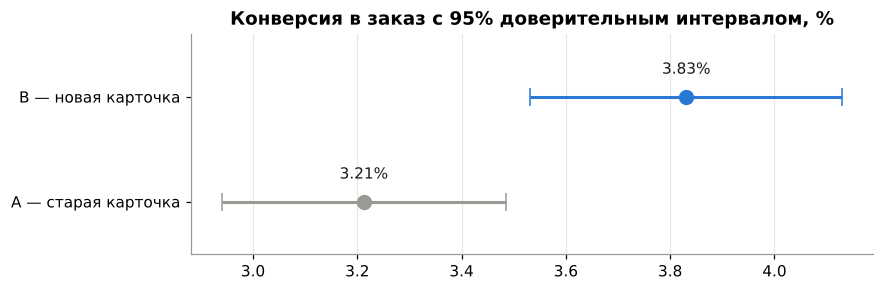

In [7]:
fig, ax = plt.subplots(figsize=(8, 2.6))
for i, (grp, col) in enumerate([("A", A_COL), ("B", B_COL)]):
    p, n = (pA, nA) if grp == "A" else (pB, nB)
    half = stats.norm.ppf(0.975) * np.sqrt(p * (1 - p) / n)
    ax.errorbar(p * 100, i, xerr=half * 100, fmt="o", color=col, ms=9, capsize=6, lw=2)
    ax.text(p * 100, i + 0.22, f"{p*100:.2f}%", ha="center", color="#1a1a19")
ax.set_yticks([0, 1], ["A — старая карточка", "B — новая карточка"]); ax.set_ylim(-0.5, 1.6)
ax.set_title("Конверсия в заказ с 95% доверительным интервалом, %")
ax.grid(axis="y", visible=False)
plt.show()

Конверсия выросла статистически значимо: p-value много меньше 0,05, а доверительный интервал разницы целиком выше нуля. Интервалы групп на графике не пересекаются.

## 4. Дополнительная метрика: выручка на посетителя

Выручка распределена очень неравномерно: у 96% посетителей она нулевая, а у купивших сильно разбросана. Для такой метрики t-тест ненадёжен, поэтому доверительный интервал считаю **бутстрепом**: 10 000 раз пересобираю выборки с повторением и смотрю, как распределена разница средних.

ARPU: A = 86.3 ₽, B = 107.2 ₽, разница +20.9 ₽ (+24.2%)
95% бутстреп-интервал разницы: [+7.3; +34.1] ₽
Манн — Уитни: p-value = 0.0025


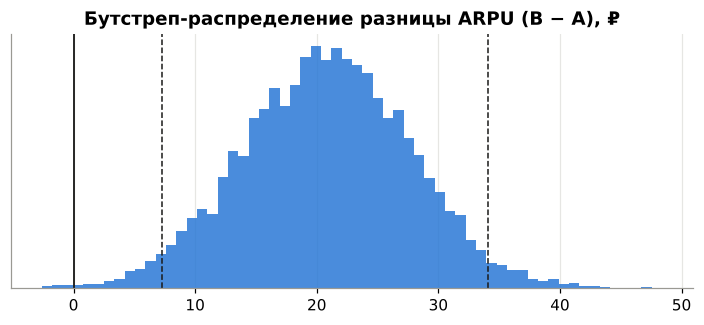

In [8]:
revA = ab.loc[ab.group == "A", "revenue"].values
revB = ab.loc[ab.group == "B", "revenue"].values
boot = np.array([rng.choice(revB, len(revB)).mean() - rng.choice(revA, len(revA)).mean() for _ in range(10_000)])
ci_arpu = np.percentile(boot, [2.5, 97.5])
mw_p = stats.mannwhitneyu(revB, revA, alternative="two-sided").pvalue
print(f"ARPU: A = {revA.mean():.1f} ₽, B = {revB.mean():.1f} ₽, разница {revB.mean() - revA.mean():+.1f} ₽ ({revB.mean() / revA.mean() - 1:+.1%})")
print(f"95% бутстреп-интервал разницы: [{ci_arpu[0]:+.1f}; {ci_arpu[1]:+.1f}] ₽")
print(f"Манн — Уитни: p-value = {mw_p:.4f}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(boot, bins=60, color=B_COL, alpha=0.85)
ax.axvline(0, color="#1a1a19", lw=1.2)
for v in ci_arpu:
    ax.axvline(v, color="#1a1a19", lw=1, ls="--")
ax.set_title("Бутстреп-распределение разницы ARPU (B − A), ₽"); ax.set_yticks([])
plt.show()

## 5. Контрольные метрики: средний чек и возвраты

In [9]:
buyers = ab[ab.converted == 1]
aovA, aovB = buyers.loc[buyers.group == "A", "revenue"], buyers.loc[buyers.group == "B", "revenue"]
t_p = stats.ttest_ind(aovB, aovA, equal_var=False).pvalue
retA, retB = buyers.groupby("group").returned.mean()
ret_p = stats.chi2_contingency(pd.crosstab(buyers.group, buyers.returned))[1]
pd.DataFrame({
    "A": [f"{aovA.mean():,.0f} ₽".replace(",", " "), f"{retA:.1%}"],
    "B": [f"{aovB.mean():,.0f} ₽".replace(",", " "), f"{retB:.1%}"],
    "p-value": [round(t_p, 2), round(ret_p, 2)],
    "вывод": ["не изменился" if t_p > ALPHA else "изменился", "не выросли" if retB <= retA or ret_p > ALPHA else "выросли!"],
}, index=["средний чек", "доля возвратов"])

,A,B,p-value,вывод
средний чек,2 687 ₽,2 799 ₽,0.29,не изменился
доля возвратов,8.7%,5.4%,0.04,не выросли


Средний чек не изменился. Доля возвратов в группе B даже ниже (p = 0,04), то есть контрольная метрика точно не ухудшилась. Записывать снижение возвратов в эффект новой карточки я бы не стал: мы проверяем сразу несколько метрик, и случайная значимость на одной из них ожидаема (при четырёх метриках шанс хотя бы одного ложного срабатывания ≈ 19%). Это гипотеза для отдельного теста, а не вывод.

## 6. Почему нельзя останавливать тест, как только «стало значимо»

Пересчитываю p-value накопительно по дням, как если бы менеджер смотрел на дашборд каждое утро.

Впервые p < 0,05 на 8-й день; относительный рост в первую неделю колебался от +15% до +29%


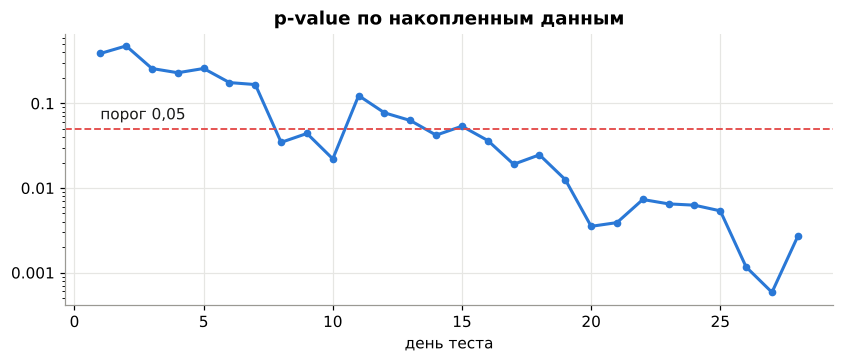

In [10]:
daily = []
for d in sorted(ab.first_visit.unique()):
    part = ab[ab.first_visit <= d]
    c = part.groupby("group").converted.agg(["sum", "count"])
    x, n = c["sum"].values, c["count"].values
    pp = x.sum() / n.sum()
    zz = (x[1] / n[1] - x[0] / n[0]) / np.sqrt(pp * (1 - pp) * (1 / n[0] + 1 / n[1]))
    daily.append({"день": (d - ab.first_visit.min()).days + 1, "p": 2 * (1 - stats.norm.cdf(abs(zz))),
                  "uplift": x[1] / n[1] / (x[0] / n[0]) - 1})
daily = pd.DataFrame(daily)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(daily["день"], daily.p, color=B_COL, lw=2, marker="o", ms=4)
ax.axhline(0.05, color="#e34948", lw=1.2, ls="--")
ax.text(1, 0.065, "порог 0,05", color="#1a1a19")
ax.set_yscale("log"); ax.set_xlabel("день теста"); ax.set_title("p-value по накопленным данным")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
plt.show()
first_sig = daily.loc[daily.p < 0.05, "день"].min()
print(f"Впервые p < 0,05 на {first_sig}-й день; относительный рост в первую неделю колебался "
      f"от {daily.uplift[:7].min():+.0%} до {daily.uplift[:7].max():+.0%}")

Здесь это видно наглядно: на 8-й день p-value впервые опустилось ниже 0,05, а на 11-й снова поднялось до 0,12. Остановись менеджер на 8-й день, он принял бы решение на неустойчивых данных; повезло, что эффект оказался настоящим. В первые дни p-value и оценка эффекта скачут. Если проверять результат каждый день и остановиться при первом p < 0,05, вероятность ложного «успеха» вырастает с 5% до 20–30%. Поэтому размер выборки и срок фиксируются заранее, а решение принимается только по итогам всего срока. Если нужно смотреть промежуточные результаты, используют последовательные методы с поправкой порога (например, O'Brien — Fleming).

## 7. Срезы: мобильные и десктоп

Срезы смотрю для понимания, а не для поиска «где значимо». При двух срезах применяю поправку Бонферрони: порог 0,05 / 2 = 0,025.

In [11]:
rows = []
for dev, part in ab.groupby("device"):
    c = part.groupby("group").converted.agg(["sum", "count"])
    x, n = c["sum"].values, c["count"].values
    pp = x.sum() / n.sum()
    zz = (x[1] / n[1] - x[0] / n[0]) / np.sqrt(pp * (1 - pp) * (1 / n[0] + 1 / n[1]))
    pv = 2 * (1 - stats.norm.cdf(abs(zz)))
    rows.append({"срез": dev, "посетителей": n.sum(), "конверсия A, %": x[0] / n[0] * 100, "конверсия B, %": x[1] / n[1] * 100,
                 "разница, п.п.": (x[1] / n[1] - x[0] / n[0]) * 100, "p-value": pv, "значимо при 0,025": pv < 0.025})
pd.set_option("display.width", 200)
pd.DataFrame(rows).round(3)

,срез,посетителей,"конверсия A, %","конверсия B, %","разница, п.п.",p-value,"значимо при 0,025"
0,desktop,10200,3.647,4.436,0.789,0.043,False
1,mobile,21800,3.011,3.546,0.535,0.026,False


Внутри каждого среза разница направлена в ту же сторону (+0,5 п.п. на мобильных, +0,8 п.п. на десктопе), но по отдельности не проходит порог: в срезе посетителей в 1,5–3 раза меньше, и мощности не хватает. Это нормально. Вывод делаем по всей выборке, на которую рассчитывали тест, а срезы показывают, что эффект не держится на одном типе устройств.

## 8. Решение и деньги

Переводим результат в рубли с консервативной оценкой: берём **нижнюю** границу доверительного интервала роста конверсии, а не точечную оценку.

In [12]:
visitors_month = 1150 * 30
aov = buyers.revenue.mean()
margin = 0.33                                   # маржинальность сайта из SQL-анализа
extra_orders_low = visitors_month * ci[0]
extra_orders_mid = visitors_month * (pB - pA)
production_cost = 105 * 2500                    # видео и фото для 105 SKU, разово
for name, eo in [("консервативно (нижняя граница)", extra_orders_low), ("точечная оценка", extra_orders_mid)]:
    profit = eo * aov * margin
    rub = lambda v: f"{v:,.0f}".replace(",", " ")
    print(f"{name}: +{eo:.0f} заказов/мес, +{rub(eo * aov)} ₽ выручки, +{rub(profit)} ₽ маржи/мес; "
          f"съёмка окупится за {production_cost / profit:.1f} мес".replace(".", ","))

консервативно (нижняя граница): +74 заказов/мес, +203 023 ₽ выручки, +66 998 ₽ маржи/мес; съёмка окупится за 3,9 мес
точечная оценка: +213 заказов/мес, +586 015 ₽ выручки, +193 385 ₽ маржи/мес; съёмка окупится за 1,4 мес


### Итог

**Решение: раскатить новую карточку на все товары сайта.**

- Конверсия выросла с 3,21% до 3,83% (+0,62 п.п., +19%). Эффект статистически значим, и даже нижняя граница интервала положительна.
- Выручка на посетителя выросла на 24% (бутстреп-интервал +7…+34 ₽). Средний чек не изменился, возвраты не выросли: рост дают дополнительные заказы.
- Разбиение корректно: SRM нет, группы сбалансированы по устройствам и источникам.
- Даже по консервативной оценке съёмка видео для 105 SKU (≈260 тыс. ₽) окупается примерно за 4 месяца, по точечной — за полтора.

**Ограничения.** Тест шёл в августе, в межсезонье. В декабре поведение покупателей другое, поэтому после раскатки стоит оставить 5–10% трафика на старой карточке (holdout) и проверить, что эффект сохраняется в сезон.

**Связанные проекты:** [SQL-анализ каналов](../sql-marketplace/): почему сайт — самый маржинальный канал; [исследовательский анализ](../python-eda/eda.ipynb): откуда берутся возвраты.